We consider a series of buttons with probabilities $p_j$ drawn form a single distribution. We assume that this distribution is a beta distribution with some unknown hyperparameters $\alpha$ and $\beta$, which we will try to learn statistically. We will assume an unspecified prior for hyperparameters $\alpha$ and $\beta$, we will call it $P(\alpha, \beta)$. We can summarize the model with the following hierarchical diagram

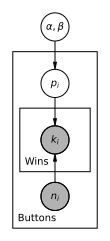

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

import daft

pgm = daft.PGM()
pgm.add_node("ab", r"$\alpha,\beta$", 0, 2)
pgm.add_node("p", r"$p_i$", 0, 1)
pgm.add_node("n", r"$n_i$", 0, -1, observed=True)
pgm.add_node("k", r"$k_i$", 0, 0, observed=True)

pgm.add_edge("ab", "p")
pgm.add_edge("p", "k")
pgm.add_edge("n", "k")

pgm.add_plate([-0.625,-0.5625, 1.25, 1.125], label=r"Wins")
pgm.add_plate([-0.75, -1.5625, 1.5, 3.125], label=r"Buttons")
pgm.render();

We observe a series of $N$ buttons labeled with an index $i$. We press each button $n_i$ times and observe $k_i$ successes. According to our model the likelihood for a button with probability $p_i$ is given by

$$
k_i, n_i | p_i \sim B(k_i, n_i| p_i) = \frac{n_i!}{k_i! (n_i - k_i)!} p_i^{k_i} (1 - p_i)^{n_i - k_i}.
$$

The button itself is drawn from a beta distribution and therefore the likelihood for the probability $p_i$ given hyperparameters $\alpha$ and $\beta$ is given by 

$$
p_i | \alpha, \beta \sim Beta(p_i|\alpha,\beta) = \frac{1}{B(\alpha, \beta)} p_i^{\alpha-1} (1 - p_i)^{\beta-1},
$$

where $Beta(\alpha, \beta)$ is the Beta function

$$
B(\alpha, \beta) = \frac{\Gamma(\alpha)\Gamma(\beta)}{\Gamma(\alpha+\beta)}.
$$

The prior for hyperparameters $\alpha$ and $\beta$ is, in turn, given by some probability distribution 

$$
\alpha,\beta \sim P(\alpha, \beta).
$$

Using all that we can find the posterior distribution for $\{p_i\}$, $\alpha$ and $\beta$

$$
P(\{p_i\}, \alpha, \beta| \{k_i\}, \{n_i\}) = \frac{\left[\prod\limits_i B(k_i, n_i| p_i) Beta(p_i|\alpha, \beta)\right] P(\alpha, \beta)}{P(\{k_i\}, \{n_i\})}.
$$

We are primarily interested in finding out posterior distribution for the hyperparameters, so we integrate out $\{p_i\}$, the posterior is then

$$
P(\alpha, \beta| \{k_i\}, \{n_i\}) = \frac{\prod\limits_i B(k_i, n_i| \alpha, \beta) P(\alpha, \beta)}{P(\{k_i\}, \{n_i\})} = \frac{\prod\limits_i B(k_i, n_i| \alpha, \beta) P(\alpha, \beta)}{\int \prod\limits_i B(k_i, n_i| \alpha, \beta) P(\alpha, \beta) d\alpha d\beta},
$$

where the cumulative likelihood for a button is given by the expression

$$
B(k_i, n_i| \alpha, \beta) = \int B(k_i, n_i| p_i) Beta(p_i|\alpha,\beta) dp_i = \frac{n_i!}{k_i! (n_i-k_i)!} \frac{B(\alpha + k_i, \beta + n_i - k_i)}{B(\alpha. \beta)}.
$$

Using the posterior for the hyperparameters we can, in principle, find posterior distributions for individual probabilities $p_i$

$$
P(p_i | \{k_i\}, \{n_i\}) ) = \int P(p_i | k_i, n_i, \alpha, \beta) P(\alpha, \beta| \{k_i\}, \{n_i\}),
$$

where

$$
P(p_i | k_i, n_i, \alpha, \beta) = \frac{B(k_i, n_i| p_i) Beta(p_i | \alpha, \beta)}{P(k_i, n_i| \alpha, \beta)} = Beta(p_i | \alpha + k_i, \beta + n_i - k_i).
$$

For our purposes, however, we will not be interested in inferring the whole posterior for $p_i$, we only need the probabilities of winning and failing at the next button press and the average reward at the next step (which is equal to probability of winning). The probability of getting a reward at the next step $p_{next}$ is equal to

$$
p_{next}(\alpha, \beta) = \int_0^1 p_i P(p_i | k_i, n_i, \alpha, \beta) dp_i = \frac{B(\alpha + k_i + 1, \beta + n_i - k_i)}{B(\alpha + k_i, \beta + n_i - k_i)} = \frac{\alpha + k_i}{\alpha + \beta + n_i}.
$$

The probability of not getting a reward at the next step, therefore, is $1 - p_{next}$.

Now we return to the issue of the prior on hyperparameters. We take the following hyperpriors

$$
\begin{split}
&\alpha \sim \mathrm{Gamma}(\alpha| k_1, \theta) = \frac{\alpha^{k_1-1}}{\Gamma(k_1) \theta^{k_1}} e^{- \frac{\alpha}{\theta}},\\
&\beta \sim \mathrm{Gamma}(\beta| k_2, \theta) = \frac{\beta^{k_2-1}}{\Gamma(k_2) \theta^{k_2}} e^{- \frac{\beta}{\theta}},
\end{split}
$$

Hyperparameters itself are highly correlated, to disentangle the correlation we introduce new variables $u$ and $v$

$$
u = \frac{\alpha}{\alpha + \beta},\qquad v = \alpha + \beta,
$$

here $u$ represents the mean probability of the buttons distribution and $v$ represents the number of buttons. For the new parameters the prior becomes

$$
\begin{split}
&u \sim \mathrm{Beta}(u|k_1, k_2) = \frac{1}{B(k_1,k_2)} u^{k_1-1} (1-u)^{k_2-1},\\
&v \sim \mathrm{Gamma}(v| k_1+k_2, \theta) = \frac{v^{k_1+k_2-1}}{\Gamma(k_1+k_2) \theta^{k_1+k_2}} e^{- \frac{v}{\theta}},
\end{split}
$$

In practice, for simplicity we are going to take empirical Bayes approach; instead of considering posterior distribution for $\alpha$ and $\beta$, we are going to use MAP values for $\alpha$ and $\beta$. Log posterior for $\alpha$ and $\beta$ reads

$$
\log P(\alpha, \beta| \{k_i\}, \{n_i\}) = \sum_i \log B(\alpha + k_i, \beta + n_i - k_i) - N \log B(\alpha, \beta) + \log P(\alpha, \beta) + const,
$$

where we omit the terms that do not depend on $\alpha$ and $\beta$. Maximizing this function we find MAP values $\alpha^*$ and $\beta^*$. We find the posterior for the probabilities of individual buttons $p_i$ as

$$
P(p_i | \{k_i\}, \{n_i\}) = Beta(p_i | \alpha^* + k_i, \beta^* + n_i - k_i),
$$

and therefore the probability of receiving the reward from a button with $n_i$ presses and $k_i$ successes is 

$$
p_{next} =  \frac{\alpha^* + k_i}{\alpha^* + \beta^* + n_i}.
$$

This method has one sufficient caveat. Let us consider the likely scenario when after a single press on the button we get no reward. In all situations an optimal strategy would be to move on. The cumulative likelihood in this case would be

$$
B(0, 1| \alpha, \beta) = \frac{\beta}{\alpha+\beta},
$$

we see that for a prior which does not discourage $\beta$ close to zero (for instance if the prior is flat around $\beta = 0$) the inferred values of $\beta$ will be close to zero, which makes the policy overconfident in buttons having a small success probability. Therefore we will pick $k_1 = k_2 = 2$. We will keep $\theta$ equal the number of buttons we have observed so far.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma
from scipy.special import beta as beta_fnc
from scipy.special import polygamma
from scipy.optimize import fmin
from scipy.optimize import minimize

def log_prior(alpha, beta, k, theta):
    #return (k-2)*np.log(alpha+beta) - (alpha + beta)/theta
    return (k-1)*np.log(alpha*beta) - (alpha + beta)/theta

def log_prior_hessian(alpha, beta, k, theta):
    #return -(k-2)/((alpha+beta)**2)*np.full((2,2), 1)
    return -(k-1)*np.diag([1/(alpha**2), 1/(beta**2)])

def log_posterior(alpha, beta, data, k=1, th=10):
    if (np.array(alpha) <= 0.0).any()  or (np.array(beta) <= 0.0).any():
        return -np.inf
    betas = [beta_fnc(alpha + data[i,1], beta + data[i,0] - data[i,1]) for i in range(len(data))]
    return sum(np.log(betas)) - len(data)*np.log(beta_fnc(alpha, beta)) + log_prior(alpha, beta, k, th)
                

def log_beta_hessian(x, y):
    return np.diag([polygamma(1, x), polygamma(1, y)]) - polygamma(1, x+y)

def fisher_matrix(alpha, beta, data, k=1, th=10):
    log_beta_hessians = [log_beta_hessian(alpha + data[i,1], beta + data[i,0] - data[i,1]) for i in range(len(data))]
    return - np.sum(log_beta_hessians, axis=0) + len(data)*log_beta_hessian(alpha, beta) -\
                log_prior_hessian(alpha, beta, k, th) 

First we generate a sequence of buttons and button presses and try to infer the hyperparameters

In [3]:
import scipy.stats as stats
from numpy.random import default_rng

def generate_button_sequence(alpha_true, beta_true, N, press_range=(100, 200)):
    b_dist = stats.beta(alpha_true, beta_true)
    
    rng = np.random.default_rng()
    button_p = b_dist.rvs(size=N, random_state=rng)
    presses = np.random.randint(press_range[0], press_range[1], size=N)
    
    observ = []
    for i in range(N):
        btn = stats.binom(presses[i], button_p[i])
        observ.append([presses[i],btn.rvs(random_state=rng)])

    return (np.array(observ), button_p)

In [4]:
alpha_true = 3.5
beta_true = 1.5
buttons_n = 20

observ, true_p = generate_button_sequence(alpha_true, beta_true, buttons_n, press_range=(1, 50))

In [5]:
map_ab = fmin(lambda x: -log_posterior(x[0], x[1], observ, 2,  len(observ)), [1.0, 1.0])
fmatrix = fisher_matrix(map_ab[0], map_ab[1], observ, 2, len(observ))
margin_err = np.sqrt(np.diag(np.linalg.inv(fmatrix)))
cond_err = np.sqrt(1.0/np.diag(fmatrix))

print("True alpha value is " + "%.3f" % alpha_true + ", true beta value is " + "%.3f" % beta_true)
print("Inferred alpha is " + "%.3f" % map_ab[0] + ", inferred beta is " + "%.3f" % map_ab[1])
print("Alpha error is " + "%.3f" % margin_err[0] + ", beta error is " + "%.3f" % margin_err[1])

Optimization terminated successfully.
         Current function value: 256.705663
         Iterations: 38
         Function evaluations: 74
True alpha value is 3.500, true beta value is 1.500
Inferred alpha is 2.006, inferred beta is 1.384
Alpha error is 0.871, beta error is 0.521


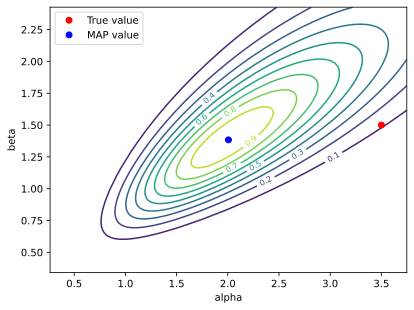

In [6]:
xfunc = np.linspace(max(0.1, map_ab[0]-2*margin_err[0]),  map_ab[0]+2*margin_err[0], 100)
yfunc = np.linspace(max(0.1, map_ab[1]-2*margin_err[1]),  map_ab[1]+2*margin_err[1], 100)
#xfunc = np.linspace(0.0000001, 5.0, 100)
#yfunc = np.linspace(0.0000001, 5.0, 100)
max_log_post = log_posterior(map_ab[0], map_ab[1], observ, 2, len(observ))

xfunc, yfunc = np.meshgrid(xfunc, yfunc)
zfunc = np.exp(log_posterior(xfunc, yfunc, observ, 2, len(observ)) - max_log_post)
plt.xlabel("alpha")
plt.ylabel("beta")
cp = plt.contour(xfunc, yfunc, zfunc, levels=10);
plt.clabel(cp, inline=True, fontsize=8);
plt.plot(alpha_true, beta_true, 'ro', label="True value");
plt.plot(map_ab[0], map_ab[1], 'bo', label="MAP value");
plt.legend(loc='upper left');
#plt.colorbar(cp);

Now we run the actual button pressing experiment with a biased button and see how well we can infer the hyperprior using actual experimental data

In [7]:
from cpp_routines import *

Here we first consider the case of optimistic buttons, the unbiased policy works here pretty well by itself

In [8]:
run_time = 500
number_of_runs = 1000
button_prior = (2, 1)
policy_prior = (1, 1)

trial_record = record_full_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior, 
                                                                      policy_prior=policy_prior)
optimal_rewards = expected_reward_table(1, 1, run_time, prior=button_prior)[:,0,0]
optimal_policy_rewards = expected_reward_table(1, 1, run_time, prior=policy_prior)[:,0,0]

rewards = np.sum(trial_record[:,:,3], axis=1)
print("The individual run length is: " + str(run_time))
print("The number of runs is: " + str(number_of_runs))
print("The theoretical reward knowing button prior is: " + str(optimal_rewards[run_time-1]))
print("The theoretical policy reward is: " + str(optimal_policy_rewards[run_time-1]))
print("The mean reward is: " + str(np.mean(rewards)))
print("The deviation is: " + str(np.std(rewards)))
print("The deviation of the mean is: " + str(np.std(rewards)/pow(len(rewards), 0.5)))

The individual run length is: 500
The number of runs is: 1000
The theoretical reward knowing button prior is: 475.50680898807343
The theoretical policy reward is: 465.3042121474984
The mean reward is: 473.367
The deviation is: 15.682420444561483
The deviation of the mean is: 0.4959216782920464


In [9]:
ind_run = trial_record[0]
buttons = (ind_run[::-1,0:3])[np.unique(ind_run[::-1,0], return_index=True)[1],:]
buttons_data = np.transpose([buttons[:,1]+buttons[:,2],buttons[:,1]])
n_buttons = len(buttons_data)
print(n_buttons)

14


In [10]:
map_ab_exp = fmin(lambda x: -log_posterior(x[0], x[1], buttons_data, 2, len(buttons_data)), [1.0, 1.0])
fmatrix_exp = fisher_matrix(map_ab_exp[0], map_ab_exp[1], buttons_data, 2, len(buttons_data))
margin_err_exp = np.sqrt(np.diag(np.linalg.inv(fmatrix_exp)))

print("MAP alpha is " + "%.3f" % map_ab_exp[0] + ", MAP beta is " + "%.3f" % map_ab_exp[1])
print("Alpha error is " + "%.3f" % margin_err_exp[0] + ", beta error is " + "%.3f" % margin_err_exp[1])
print("MAP ratio is " + "%.3f" % (map_ab_exp[0]/(map_ab_exp[0]+map_ab_exp[1])))
print("True ratio is " + "%.3f" % (button_prior[0]/(button_prior[0]+button_prior[1])))

Optimization terminated successfully.
         Current function value: 136.192770
         Iterations: 54
         Function evaluations: 104
MAP alpha is 19.506, MAP beta is 4.014
Alpha error is 12.937, beta error is 2.030
MAP ratio is 0.829
True ratio is 0.667


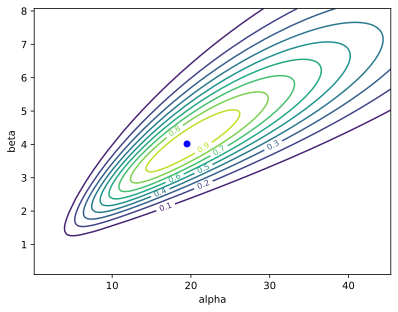

In [11]:
#xfunc = np.linspace(0.01, 2, 100)
#yfunc = np.linspace(0.01, 2, 100)
xfunc = np.linspace(max(0.1, map_ab_exp[0]-2*margin_err_exp[0]),  map_ab_exp[0]+2*margin_err_exp[0], 100)
yfunc = np.linspace(max(0.1, map_ab_exp[1]-2*margin_err_exp[1]),  map_ab_exp[1]+2*margin_err_exp[1], 100)

max_log_post = log_posterior(map_ab_exp[0], map_ab_exp[1], buttons_data, 2, len(buttons_data))

xfunc, yfunc = np.meshgrid(xfunc, yfunc)
#zfunc = log_posterior(xfunc, yfunc, buttons_data, 2, len(buttons_data))
zfunc = np.exp(log_posterior(xfunc, yfunc, buttons_data, 2, len(buttons_data)) - max_log_post)
plt.xlabel("alpha")
plt.ylabel("beta")
plt.plot(map_ab_exp[0], map_ab_exp[1], 'bo', label="MAP value");
cp = plt.contour(xfunc, yfunc, zfunc, levels=10);
plt.clabel(cp, inline=True, fontsize=8);

In [12]:
#Setting up emcee
import emcee
import corner

# create a small ball around the MLE the initialize each walker 
nwalkers, ndim = 30, 2
pos = map_ab_exp + 1e-3*map_ab_exp*np.random.randn(nwalkers, ndim)

# run emcee
sampler = emcee.EnsembleSampler(nwalkers, ndim, lambda x: log_posterior(x[0], x[1], buttons_data, 2, len(buttons_data)))
sampler.run_mcmc(pos, 2000, progress=True);

100%|██████████| 2000/2000 [00:03<00:00, 610.65it/s]


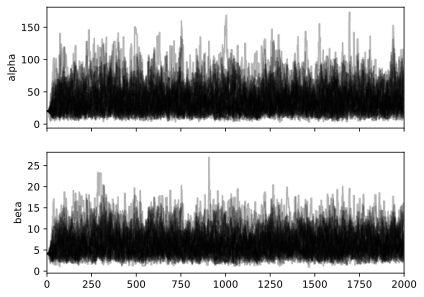

In [13]:
fig, axes = plt.subplots(ndim, sharex=True)
samples = sampler.get_chain()
labels = ["alpha", "beta"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3, rasterized=True)
    ax.set_xlim(0, 2000)
    ax.set_ylabel(labels[i])

In [14]:
tau = sampler.get_autocorr_time()
print(tau)
np.mean(sampler.acceptance_fraction)

[29.48241627 29.1952168 ]


0.6966666666666669

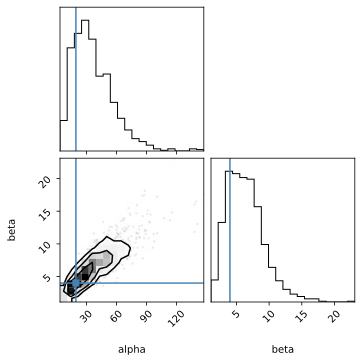

In [15]:
flat_samples = sampler.get_chain(discard=200, thin=50, flat=True)
fig = corner.corner(
    flat_samples, labels=labels, truths=map_ab_exp
);

In [16]:
print("Mean alpha is " + "%.3f" % np.mean(flat_samples[:,0]) + ", mean beta is " + "%.3f" % np.mean(flat_samples[:,1]))
print("Alpha deviation is " + "%.3f" % np.std(flat_samples[:,0]) + ", beta deviation is " + "%.3f" % np.std(flat_samples[:,1]))

Mean alpha is 36.923, mean beta is 6.398
Alpha deviation is 20.521, beta deviation is 2.857


In [17]:
print("MAP probability is " + "%.3f" % np.mean(map_ab_exp[0]/(map_ab_exp[0]+map_ab_exp[1])))
print("MCMC probability is " + "%.3f" % np.mean(flat_samples[:,0]/(flat_samples[:,0]+flat_samples[:,1])))
print("True probability is " + "%.3f" % np.mean(button_prior[0]/(button_prior[0]+button_prior[1])))

cwins = 10
cfails = 3
print("For " + str(cwins) + " wins and " + str(cfails) + " fails")
print("MAP probability is " + "%.3f" % np.mean((map_ab_exp[0]+cwins)/(map_ab_exp[0]+map_ab_exp[1]+cwins+cfails)))
print("MCMC probability is " + "%.3f" % np.mean((flat_samples[:,0]+cwins)/(flat_samples[:,0]+flat_samples[:,1]+cwins+cfails)))
print("True probability is " + "%.3f" % np.mean((button_prior[0]+cwins)/(button_prior[0]+button_prior[1]+cwins+cfails)))

MAP probability is 0.829
MCMC probability is 0.842
True probability is 0.667
For 10 wins and 3 fails
MAP probability is 0.808
MCMC probability is 0.825
True probability is 0.750


Now we consider the case of negatively biased button where the unbiased strategy significantly underperforms

In [18]:
run_time = 500
number_of_runs = 1000
button_prior = (1, 2)
policy_prior = (1, 1)

trial_record = record_full_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior, 
                                                                      policy_prior=policy_prior)
optimal_rewards = expected_reward_table(1, 1, run_time, prior=button_prior)[:,0,0]
optimal_policy_rewards = expected_reward_table(1, 1, run_time, prior=policy_prior)[:,0,0]

rewards = np.sum(trial_record[:,:,3], axis=1)
print("The individual run length is: " + str(run_time))
print("The number of runs is: " + str(number_of_runs))
print("The theoretical reward knowing button prior is: " + str(optimal_rewards[run_time-1]))
print("The theoretical policy reward is: " + str(optimal_policy_rewards[run_time-1]))
print("The mean reward is: " + str(np.mean(rewards)))
print("The deviation is: " + str(np.std(rewards)))
print("The deviation of the mean is: " + str(np.std(rewards)/pow(len(rewards), 0.5)))

The individual run length is: 500
The number of runs is: 1000
The theoretical reward knowing button prior is: 399.1509386451633
The theoretical policy reward is: 465.3042121474984
The mean reward is: 345.213
The deviation is: 73.0339621751415
The deviation of the mean is: 2.3095366702003237


In [19]:
ind_run = trial_record[1]
buttons = (ind_run[::-1,0:3])[np.unique(ind_run[::-1,0], return_index=True)[1],:]
buttons_data = np.transpose([buttons[:,1]+buttons[:,2],buttons[:,1]])
n_buttons = len(buttons_data)
print(n_buttons)

107


In [20]:
map_ab_exp = fmin(lambda x: -log_posterior(x[0], x[1], buttons_data, 2, len(buttons_data)), [1.0, 1.0])
fmatrix_exp = fisher_matrix(map_ab_exp[0], map_ab_exp[1], buttons_data, 2, len(buttons_data))
margin_err_exp = np.sqrt(np.diag(np.linalg.inv(fmatrix_exp)))

print("MAP alpha is " + "%.3f" % map_ab_exp[0] + ", MAP beta is " + "%.3f" % map_ab_exp[1])
print("Alpha error is " + "%.3f" % margin_err_exp[0] + ", beta error is " + "%.3f" % margin_err_exp[1])
print("MAP ratio is " + "%.3f" % (map_ab_exp[0]/(map_ab_exp[0]+map_ab_exp[1])))
print("True ratio is " + "%.3f" % (button_prior[0]/(button_prior[0]+button_prior[1])))

Optimization terminated successfully.
         Current function value: 191.497929
         Iterations: 44
         Function evaluations: 85
MAP alpha is 1.426, MAP beta is 2.759
Alpha error is 0.593, beta error is 0.889
MAP ratio is 0.341
True ratio is 0.333


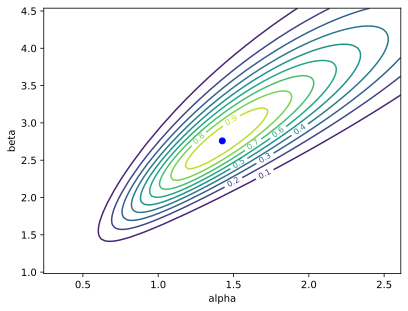

In [21]:
xfunc = np.linspace(0.01, 2, 100)
yfunc = np.linspace(0.01, 2, 100)
xfunc = np.linspace(max(0.1, map_ab_exp[0]-2*margin_err_exp[0]),  map_ab_exp[0]+2*margin_err_exp[0], 100)
yfunc = np.linspace(max(0.1, map_ab_exp[1]-2*margin_err_exp[1]),  map_ab_exp[1]+2*margin_err_exp[1], 100)

max_log_post = log_posterior(map_ab_exp[0], map_ab_exp[1], buttons_data, 2, len(buttons_data))

xfunc, yfunc = np.meshgrid(xfunc, yfunc)
zfunc = log_posterior(xfunc, yfunc, buttons_data, 2, len(buttons_data))
zfunc = np.exp(log_posterior(xfunc, yfunc, buttons_data, 2, len(buttons_data)) - max_log_post)
plt.xlabel("alpha")
plt.ylabel("beta")
plt.plot(map_ab_exp[0], map_ab_exp[1], 'bo', label="MAP value");
cp = plt.contour(xfunc, yfunc, zfunc, levels=10);
plt.clabel(cp, inline=True, fontsize=8);

In [22]:
#Setting up emcee
import emcee
import corner

# create a small ball around the MLE the initialize each walker 
nwalkers, ndim = 30, 2
pos = map_ab_exp + 1e-3*map_ab_exp*np.random.randn(nwalkers, ndim)

# run emcee
sampler = emcee.EnsembleSampler(nwalkers, ndim, lambda x: log_posterior(x[0], x[1], buttons_data, 2, len(buttons_data)))
sampler.run_mcmc(pos, 2000, progress=True);

100%|██████████| 2000/2000 [00:15<00:00, 131.42it/s]


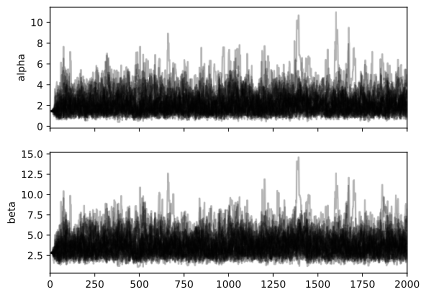

In [23]:
fig, axes = plt.subplots(ndim, sharex=True)
samples = sampler.get_chain()
labels = ["alpha", "beta"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3, rasterized=True)
    ax.set_xlim(0, 2000)
    ax.set_ylabel(labels[i])

In [24]:
tau = sampler.get_autocorr_time()
print(tau)
np.mean(sampler.acceptance_fraction)

[34.33132258 33.56319336]


0.7009500000000002

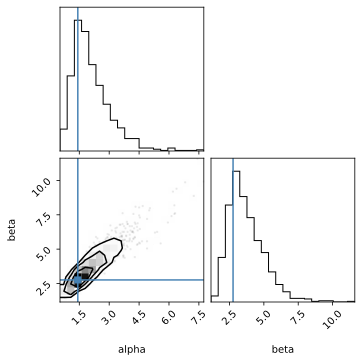

In [25]:
flat_samples = sampler.get_chain(discard=200, thin=50, flat=True)
fig = corner.corner(
    flat_samples, labels=labels, truths=map_ab_exp
);

In [26]:
print("Mean alpha is " + "%.3f" % np.mean(flat_samples[:,0]) + ", mean beta is " + "%.3f" % np.mean(flat_samples[:,1]))
print("Alpha deviation is " + "%.3f" % np.std(flat_samples[:,0]) + ", beta deviation is " + "%.3f" % np.std(flat_samples[:,1]))

Mean alpha is 2.115, mean beta is 3.719
Alpha deviation is 0.987, beta deviation is 1.316


In [27]:
print("MAP probability is " + "%.3f" % np.mean(map_ab_exp[0]/(map_ab_exp[0]+map_ab_exp[1])))
print("MCMC probability is " + "%.3f" % np.mean(flat_samples[:,0]/(flat_samples[:,0]+flat_samples[:,1])))
print("True probability is " + "%.3f" % np.mean(button_prior[0]/(button_prior[0]+button_prior[1])))

cwins = 10
cfails = 3
print("For " + str(cwins) + " wins and " + str(cfails) + " fails")
print("MAP probability is " + "%.3f" % np.mean((map_ab_exp[0]+cwins)/(map_ab_exp[0]+map_ab_exp[1]+cwins+cfails)))
print("MCMC probability is " + "%.3f" % np.mean((flat_samples[:,0]+cwins)/(flat_samples[:,0]+flat_samples[:,1]+cwins+cfails)))
print("True probability is " + "%.3f" % np.mean((button_prior[0]+cwins)/(button_prior[0]+button_prior[1]+cwins+cfails)))

MAP probability is 0.341
MCMC probability is 0.355
True probability is 0.333
For 10 wins and 3 fails
MAP probability is 0.665
MCMC probability is 0.646
True probability is 0.688


Here we actually implement Bernoulli with learning strategy

In optimistic buttons distribution case (so buttons are drawn from a distribution with the mean above 0.5) both unbiased strategy and learning strategy perform comparably

In [28]:
run_time = 100
number_of_runs = 500
button_prior = (3, 1)

rewards_ub = run_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior)
rewards_meta = run_meta_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior)

val_max = expected_reward_table(1, 1, run_time, prior=button_prior)[:,0,0]
val_ub = expected_reward_table(1, 1, run_time, prior=(1, 1))[:,0,0]

print("The individual run length is: " + str(run_time))
print("The number of runs is: " + str(number_of_runs))
print("The optimal button reward is: " + str(val_max[-1]))
print("The expected unbiased reward is: " + str(val_ub[-1]))
print("The mean unbiased button reward is: " + str(np.mean(rewards_ub)))
print("The mean learning button reward is: " + str(np.mean(rewards_meta)))
print("The unbiased mean deviation is: " + str(np.std(rewards_ub)/(len(rewards)**0.5)))
print("The learning mean deviation is: " + str(np.std(rewards_meta)/(len(rewards_meta)**0.5)))

The individual run length is: 100
The number of runs is: 500
The optimal button reward is: 91.98729714784128
The expected unbiased reward is: 85.53483300174244
The mean unbiased button reward is: 91.196
The mean learning button reward is: 90.444
The unbiased mean deviation is: 0.18138793785695892
The learning mean deviation is: 0.3294931380165602


In slightly pessimistic buttons case both unbiased strategy and learning strategy perform comparably, the learning strategy slighlty underperforms

In [29]:
run_time = 100
number_of_runs = 500
button_prior = (1, 1.5)

rewards_ub = run_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior)
rewards_meta = run_meta_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior)

val_max = expected_reward_table(1, 1, run_time, prior=button_prior)[:,0,0]
val_ub = expected_reward_table(1, 1, run_time, prior=(1, 1))[:,0,0]

print("The individual run length is: " + str(run_time))
print("The number of runs is: " + str(number_of_runs))
print("The optimal button reward is: " + str(val_max[-1]))
print("The expected unbiased reward is: " + str(val_ub[-1]))
print("The mean unbiased button reward is: " + str(np.mean(rewards_ub)))
print("The mean learning button reward is: " + str(np.mean(rewards_meta)))
print("The unbiased mean deviation is: " + str(np.std(rewards_ub)/(len(rewards)**0.5)))
print("The learning mean deviation is: " + str(np.std(rewards_meta)/(len(rewards_meta)**0.5)))

The individual run length is: 100
The number of runs is: 500
The optimal button reward is: 76.02083184516789
The expected unbiased reward is: 85.53483300174244
The mean unbiased button reward is: 75.264
The mean learning button reward is: 71.052
The unbiased mean deviation is: 0.4166080940164269
The learning mean deviation is: 0.6599171099463932


In significantly pessimistic buttons case both learning strategy outperforms unbiased strategy

In [30]:
run_time = 100
number_of_runs = 500
button_prior = (1, 3)

trial_record_ub = record_full_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior)
trial_record_meta = record_full_meta_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior)

rewards_ub = np.sum(trial_record_ub[:,:,3], axis=1)
rewards_meta = np.sum(trial_record_meta[:,:,3], axis=1)

val_max = expected_reward_table(1, 1, run_time, prior=button_prior)[:,0,0]
val_ub = expected_reward_table(1, 1, run_time, prior=(1, 1))[:,0,0]

print("The individual run length is: " + str(run_time))
print("The number of runs is: " + str(number_of_runs))
print("The optimal button reward is: " + str(val_max[-1]))
print("The expected unbiased reward is: " + str(val_ub[-1]))
print("The mean unbiased button reward is: " + str(np.mean(rewards_ub)))
print("The mean learning button reward is: " + str(np.mean(rewards_meta)))
print("The unbiased mean deviation is: " + str(np.std(rewards_ub)/(len(rewards)**0.5)))
print("The learning mean deviation is: " + str(np.std(rewards_meta)/(len(rewards_meta)**0.5)))

The individual run length is: 100
The number of runs is: 500
The optimal button reward is: 53.716307018782956
The expected unbiased reward is: 85.53483300174244
The mean unbiased button reward is: 41.958
The mean learning button reward is: 49.958
The unbiased mean deviation is: 0.5124960838874772
The learning mean deviation is: 0.7193945176327103


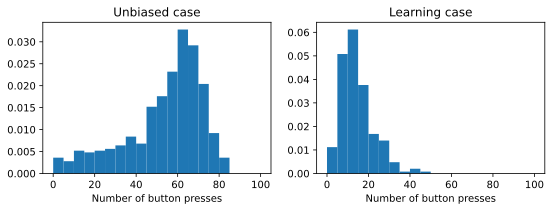

In [31]:
num_buttons_ub = np.max(trial_record_ub[:,:,0], axis=1)+1
num_buttons_meta = np.max(trial_record_meta[:,:,0], axis=1)+1

fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(221)
ax.set_title("Unbiased case")
ax.set_xlabel("Number of button presses")
ax.hist(num_buttons_ub, density=True, bins=20, range=(0, 100));

ax = fig.add_subplot(222)
ax.set_title("Learning case")
ax.set_xlabel("Number of button presses")
ax.hist(num_buttons_meta, density=True, bins=20, range=(0, 100));

There is a clear interpretation of the situation. The success of the strategy depends on picking up a good button and exploiting it the best you can. In case of unbiased buttons and optimistic buttons the unbiased policy finds such button relatively easily. However, in case of negatively biased button unbiased strategy becomes overoptimistic and switches far too often when it sees failures, while the learning strategy can adjust to that situation.